# Microproyecto 2. La tarea de clasificación: árboles de decisión y K-vecinos más cercanos

### Trabajo presentado por David Sebastián Mendoza Cruz

En el presente trabajo, identificaremos señales de riesgo de la hipertensión utilizando las técnicas de árboles de decisión y K-vecinos más cercanos vistas en las sesiones sincrónicas y asincrónicas.

### Disclaimer

En este cuaderno he tomado porciones de código de los cuadernos compartidos para la materia Introducción al Machine Learning con propósitos meramente de la actividad, adicionalmente seguiré el flujo de ejecución de los cuadernos para seguir un orden dentro del proyecto.

Hice uso de herramientas de IAG (ChatGPT), el uso fue para redactar las celdas aquí descritas y parahacer preguntas sobre las técnicas.

---

## Preparación del entorno

Importaremos las librerías presentadas en las sesiones que necesitaremos para realizar el ejercicio. Tal y como se solicita utiliaremos una semilla de 77 (random_state)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

%matplotlib inline
sns.set_theme(style="whitegrid")
# Solicitado en el enunciado
RANDOM_STATE = 77

Importamos esta librería adicional para revisar la consistencia en los datos

In [2]:
from pandas.api.types import is_numeric_dtype

In [3]:
from importlib.metadata import version
for libreria in ["pandas", "numpy", "scikit-learn", "seaborn"]:
    print(f"{libreria}: {version(libreria)}")

pandas: 3.0.5
numpy: 2.5.1
scikit-learn: 1.9.0
seaborn: 0.13.2


## Comprensión del problema

Estimar el riesgo de hipertensión en pacientes considerando una serie de factores biológicos y fisiológicos. Dentro de esta estimación se pretende cumplir con dos objetivos:
1. Realizar una detección temprana de la enfermedad, puesto que en muchas situaciones los diagnósticos se dan ya en etapas muy avanzadas de la enfermedad.
2. Determinar qué datos son más determinantes en el desarrollo de la hipertensión según los datos que tenemos a nuestra disposición.

## Comprensión de los datos



In [4]:
df = pd.read_csv("data/Datos_hipertension.csv", sep=";")
data = df.copy()
data.head()

,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duracion_Sueno,BMI,Medicacion,Historia_Familiar,Actividad_Fisica,Fumador,Glucosa,Enfermedad_Corazon,Hipertension
0,69,8.0,9,242.4,6.4,25.8,Ninguna,Si,Baja,No,127.8,Si,Si
1,32,11.7,10,177.2,5.4,23.4,Ninguna,No,Baja,No,105.9,No,No
2,78,9.5,3,193.0,7.1,18.7,Ninguna,No,Moderada,No,102.7,No,No
3,38,10.0,10,268.1,4.2,22.1,InhibidorACE,No,Baja,No,99.0,No,Si
4,41,9.8,1,175.3,5.8,16.2,Otro,No,Moderada,No,101.5,No,No


Añadimos además el diccionario de los datos para tener una mayor claridad de cada variable.

In [5]:
dictio = pd.read_excel('./data/Diccionario_Datos_hipertension.xlsx')
pd.set_option('display.max_colwidth', None)
dictio

,Variable,Tipo de variable,Descripción
0,Edad,Numérica entera,Edad registrada para el individuo.
1,Ingesta_Sal,Numérica continua,Nivel de consumo de sal registrado para el individuo.
2,Nivel_Stres,Categórica ordinal,"Nivel de estrés registrado para el individuo, representado mediante una escala numérica."
3,Colesterol,Numérica continua,Nivel de colesterol registrado para el individuo.
4,Duración_Sueño,Numérica continua,Duración habitual del sueño registrada para el individuo.
5,BMI,Numérica continua,Índice de masa corporal. Se utiliza como indicador de la relación entre peso y estatura en adultos.
6,Medicación,Categórica nominal,"Tipo de tratamiento farmacológico registrado para el individuo. Incluye las categorías inhibidor de la ECA, bloqueador beta, diurético, otro y ninguna medicación."
7,Historia_Familiar,Categórica nominal,Indica si el individuo reporta antecedentes familiares de hipertensión.
8,Actividad_Fisica,Categórica ordinal,"Nivel de actividad física del individuo, clasificado como bajo, moderado o alto."
9,Fumador,Categórica nominal,Indica si el individuo es fumador.


In [6]:
data.shape

(1990, 13)

En esta ocasión contamos con 1990 registros, además tendremos 13 columnas.

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1990 entries, 0 to 1989
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Edad                1990 non-null   int64  
 1   Ingesta_Sal         1990 non-null   float64
 2   Nivel_Stres         1990 non-null   int64  
 3   Colesterol          1990 non-null   float64
 4   Duracion_Sueno      1990 non-null   float64
 5   BMI                 1990 non-null   float64
 6   Medicacion          1990 non-null   str    
 7   Historia_Familiar   1990 non-null   str    
 8   Actividad_Fisica    1990 non-null   str    
 9   Fumador             1990 non-null   str    
 10  Glucosa             1990 non-null   float64
 11  Enfermedad_Corazon  1990 non-null   str    
 12  Hipertension        1990 non-null   str    
dtypes: float64(5), int64(2), str(6)
memory usage: 202.2 KB


En este caso vemos que tenemos diferentes de tipos de variables. Es importante apreciar que tenemos 6 datos registrados de tipo categórico. Adicionalmente, no contamos con una variable identificadora o ID.

Revisemos ahora las estadísticas para los datos de tipo estadístico.

In [8]:
data.describe()

,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duracion_Sueno,BMI,Glucosa
count,1990.000000,1990.000000,1990.000000,1990.000000,1990.000000,1990.000000,1990.000000
mean,50.379397,8.531608,4.974372,209.526935,6.452613,26.013869,105.642211
std,19.439669,1.994245,3.144396,75.791456,1.540354,4.507425,22.541122
min,18.000000,2.500000,0.000000,121.200000,1.500000,11.900000,70.000000
25%,34.000000,7.200000,2.000000,181.325000,5.400000,23.000000,89.200000
50%,50.000000,8.500000,5.000000,204.400000,6.500000,25.900000,102.500000
75%,67.000000,9.900000,8.000000,231.700000,7.500000,29.100000,119.875000
max,84.000000,16.400000,10.000000,2360.000000,11.400000,41.900000,196.100000


1. Vemos que en la variable Ingesta_Sal existe un valor máximo bastante alto respecto a la media.

2. En las variable Nivel_Stres el valor mínimo es 0.

3. La variable Colesterol presenta una desviación estándar alta, así como un máximo de 2360 muy alejado del resto de la distribución de los datos.

4. La variable Duracion_Sueno presenta un valor mínimo de ~1.54 el cuál es un nivel muy bajo de sueño para una persona en general.

**Opinión experta**

Utilizando la información suministrada por los expertos en los foros de discusión tenemos respuesta a estos hallazgos que encontramos en las estadísticas:

1. El valor máximo de Ingesta_Sal es totalmente plausible, está dentro de valores posibles para el contexto de este problema. En general puede deberse a problemas alimenticios.

2. La variable Nivel_Stres fue codificada por expertos, por lo que los valores de 0 son posibles y válidos, puesto que presentan una medida **diferente** a decir que no existe estrés en el cuerpo (fenómeno biológicamente imposible), pero no es el caso. Es por esto que en el diccionario de datos se muestra como una variable categórica ordinal.

3. Este dato en definitiva se trata de un dato no válido. En un análisis posterior de esta variable veremos si hay más datos alejados de la distribución del resto de los datos.

4. El valor mínimo en Duracion_Sueno es completamente válido de manera similar a lo presentado en el primer punto. En este caso el contexto dice que la hipertensión está relacionada a la privación del sueño y al insomnio severo.  

### Conociendo más la variable objetivo

En este caso tenemos una variable categórica, cuyo etiquetado es binario Si, No para seterminar si se tiene hipertensión o no, veamos como se distrubyen estas categorías.

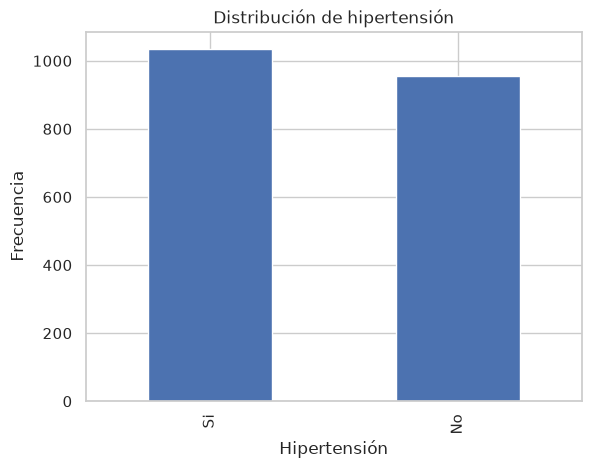

Hipertension
Si    1034
No     956
Name: count, dtype: int64

In [9]:
data["Hipertension"].value_counts().plot(kind="bar")

plt.title("Distribución de hipertensión")
plt.xlabel("Hipertensión")
plt.ylabel("Frecuencia")
plt.show()

data["Hipertension"].value_counts()

En este caso hay una distribución uniforme, aunque la mayoría de los datos presentan más casos de hipertensión.

### Fuga de datos

Pese a que la variable Medicacion contenga productos relacionados con la baja de la tensión, la opinión experta recomienda conservar estos datos para el estudio. Es decir, no hay ninguna fuga de datos

## Calidad y Limpieza de los datos

Revisemos ahora las 4 dimensiones de calidad para los datos:

* **Unicidad:** Dado que aquí no existe algo parecido a una variable de tipo ID como en el primer microproyecto procedemos a revisar duplicados para todas las 13 columnas.

In [31]:
n_duplicadas = data.duplicated().sum()
print(f"Filas idénticas (duplicadas): {n_duplicadas}")

Filas idénticas (duplicadas): 0


Vemos que existen 4 registros que coinciden en sus valores en todas las 13 columnas, a una ausencia de ID debemos hacer una consulta a los expertos para saber a qué se debe esto.

**Opinión experta**

Efectivamente esto se trata de un error a la hora de escribir estos.

**Decisión**

Vamos a eliminar los datos duplicados. Adicional a la opinión de la persona experta en el dominio, los datos no representan un porcentaje grande del total de los registros.

In [18]:
data = data.drop_duplicates()
n_duplicadas = data.duplicated().sum()
print(f"Filas idénticas (duplicadas): {n_duplicadas}")

Filas idénticas (duplicadas): 0


* **Consistencia:** En este caso, dado que tenemos columnas numéricas y no numéricas, vamos analizar la consistencia del tipo de dato en ambas categorías:

Para los datos numéricos

In [19]:
# Para los datos numéricos
tipos = data.dtypes
numericas = tipos[tipos.apply(is_numeric_dtype)]
data_numericas = data[numericas.index].copy()

print("Columnas numéricas encontradas: ")
print(numericas)

data_numericas.head()

Columnas numéricas encontradas: 
Edad                int64
Ingesta_Sal       float64
Nivel_Stres         int64
Colesterol        float64
Duracion_Sueno    float64
BMI               float64
Glucosa           float64
dtype: object


,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duracion_Sueno,BMI,Glucosa
0,69,8.0,9,242.4,6.4,25.8,127.8
1,32,11.7,10,177.2,5.4,23.4,105.9
2,78,9.5,3,193.0,7.1,18.7,102.7
3,38,10.0,10,268.1,4.2,22.1,99.0
4,41,9.8,1,175.3,5.8,16.2,101.5


Para los datos no numéricos

In [20]:
# Para los datos no numéricos
no_numericas = tipos[~tipos.apply(is_numeric_dtype)]
data_no_numericas = data[no_numericas.index].copy()

print("Columnas no numéricas encontradas:")
print(no_numericas)

data_no_numericas.head()

Columnas no numéricas encontradas:
Medicacion            str
Historia_Familiar     str
Actividad_Fisica      str
Fumador               str
Enfermedad_Corazon    str
Hipertension          str
dtype: object


,Medicacion,Historia_Familiar,Actividad_Fisica,Fumador,Enfermedad_Corazon,Hipertension
0,Ninguna,Si,Baja,No,Si,Si
1,Ninguna,No,Baja,No,No,No
2,Ninguna,No,Moderada,No,No,No
3,InhibidorACE,No,Baja,No,No,Si
4,Otro,No,Moderada,No,No,No


En este caso todas las columnas numéricas fueron marcadas como tal, del mismo modo para las columnas no numéricas. Así que no hay ningún problema de consistencia.

* **Completitud**

In [21]:
faltantes = data.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
print(faltantes[faltantes > 0] if faltantes.sum() else "  ninguno")

Valores faltantes por columna (solo las que tienen):
  ninguno


No hay ningún problema de completitud.

* **Validez**

En el proceso de comprensión de los datos dejamos pendiente revisar qué pasaba con el dato atípico máximo en la variable Colesterol. Revisemos la distribución de esta variable:

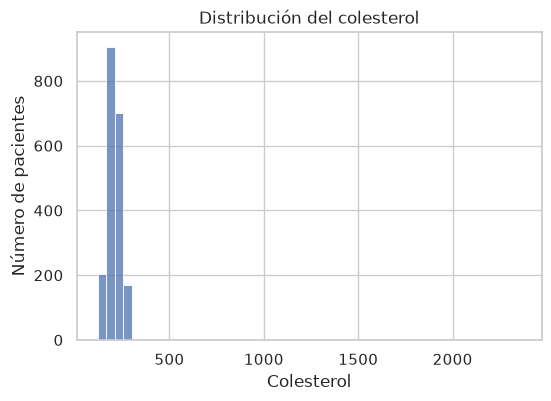

count    1986.0
mean      210.0
std        76.0
min       121.0
25%       181.0
50%       204.0
75%       232.0
max      2360.0
Name: Colesterol, dtype: float64


In [24]:
plt.figure(figsize=(6, 4))
sns.histplot(data=data, x="Colesterol", bins=50)

plt.title("Distribución del colesterol")

plt.ylabel("Número de pacientes")

plt.show()

print(data["Colesterol"].describe().round(0))

Vemos de manera más clara que el dato máximo está totalmente alejado de los demás rangos. La desviación estándar nos hace creer que puede haber más de un dato con esta característica:

In [27]:
data["Colesterol"].nlargest(5)

12     2360.0
196    1835.0
16     1597.0
211     326.3
480     307.0
Name: Colesterol, dtype: float64

Aquí observamos que son **3** los registros que están completamente separados por el resto de la distribución de los datos

**Opinión experta** 

Efectivamente estos tres datos se tratan de un errorde tipificación

**Decisión**

Estos datos deben ser eliminados puesto que son errores.

In [30]:
indices_eliminar = data["Colesterol"].nlargest(3).index

data = data.drop(indices_eliminar)

data["Colesterol"].describe().round(0)

count    1977.0
mean      207.0
std        33.0
min       121.0
25%       181.0
50%       204.0
75%       232.0
max       294.0
Name: Colesterol, dtype: float64

Vemos un cambio importante en la desviación estándar y como el valor máximo ahora está más cerca del resto de la distribución.

## Preparación de los datos

Ya adelantamos un par de tareas eliminando filas duplicadas y registros mal ingresados.

### Separar los datos

En este caso no hay ning+un inconveniente en términos de imputación ni fuga de datos.

Haremos una separación de X e y y luego haremos la partición train/test. Nuevamente el enunciado pide un 80% para entrenamiento y 20% para test

In [34]:
# (1) Separar predictoras (X) y objetivo (y).
X = data.drop(columns="Hipertension")
y = data["Hipertension"]

numericas = X.select_dtypes("number").columns.tolist()
categoricas = X.select_dtypes("str").columns.tolist()

# (2) Partir en train/test. random_state fija el resultado. 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)


print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)

Entrenamiento: (1581, 12)  Prueba: (396, 12)


In [35]:
print(numericas)
print(categoricas)

['Edad', 'Ingesta_Sal', 'Nivel_Stres', 'Colesterol', 'Duracion_Sueno', 'BMI', 'Glucosa']
['Medicacion', 'Historia_Familiar', 'Actividad_Fisica', 'Fumador', 'Enfermedad_Corazon']


## Modelado

### Con árboles de decisión

Como vimos en las sesiones los áboles no necesitan de un escalado. Preparamos su pipeline:

In [36]:
prep_arbol = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), categoricas),
])

pipeline_arbol = Pipeline([("prep", prep_arbol),
                           ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE))])

Realizamos validación cruzada

In [37]:
grid_arbol = GridSearchCV(
    pipeline_arbol,
    param_grid={
        "modelo__criterion": ["gini", "entropy"],
        "modelo__max_depth": [4, 6, 8, 10, 12],
        "modelo__min_samples_split": [3, 4, 5]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_arbol.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid_arbol.best_params_)

Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 8, 'modelo__min_samples_split': 4}


La búsqueda de hiperparámetros mediante validación cruzada determinó que la mejor configuración para el árbol de decisión utiliza el criterio de entropía, una profundidad máxima de 8 niveles y un mínimo de 4 muestras para dividir un nodo. Una profundidad de 8 niveles está en la mitad de las profundidades que le dimos a escoger, lo mismo sucede para el tamaño de las muestras.

In [38]:
print("Mejor exactitud CV (Árbol):", round(grid_arbol.best_score_, 3))

Mejor exactitud CV (Árbol): 0.895


Revisemos ahora la curva de validación fijando el criterio ganador.

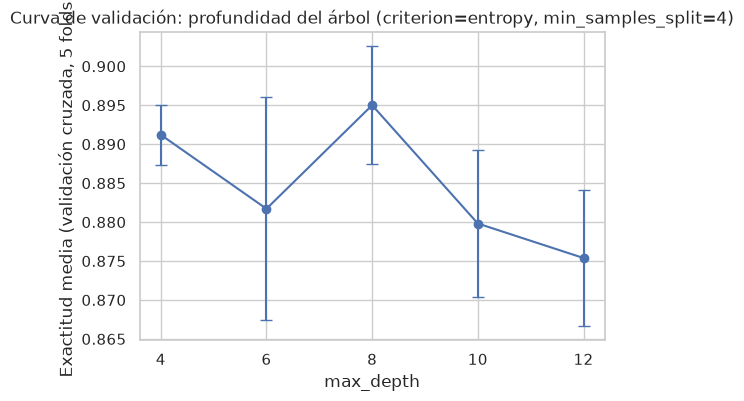

In [40]:
resultados_arbol = pd.DataFrame(grid_arbol.cv_results_)

mejor_criterio = grid_arbol.best_params_["modelo__criterion"]
mejor_min_samples = grid_arbol.best_params_["modelo__min_samples_split"]

resultados_arbol = (
    resultados_arbol[
        (resultados_arbol["param_modelo__criterion"] == mejor_criterio) &
        (resultados_arbol["param_modelo__min_samples_split"] == mejor_min_samples)
    ]
    .sort_values("param_modelo__max_depth")
)

plt.figure(figsize=(6, 4))

plt.errorbar(
    resultados_arbol["param_modelo__max_depth"].astype(float),
    resultados_arbol["mean_test_score"],
    yerr=resultados_arbol["std_test_score"],
    marker="o",
    capsize=4
)

plt.xticks(resultados_arbol["param_modelo__max_depth"].astype(int))

plt.xlabel("max_depth")
plt.ylabel("Exactitud media (validación cruzada, 5 folds)")

plt.title(
    f"Curva de validación: profundidad del árbol "
    f"(criterion={mejor_criterio}, min_samples_split={mejor_min_samples})"
)

plt.show()

Vemos que no es una completamente ascendente. Es claro que aunque es una regla decente en 4, para 6 baja mucho, en 8 está bastante bien, apartir de ahí vuelve a tener un rendimiento de bajo ajuste muy importante para 10 y para 12. El valor que mejor se ajusta es mediante validación cruzada. veamoslo en una lista:

In [41]:
resultados_arbol[["param_modelo__max_depth", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score") \
    .reset_index(drop=True)

,param_modelo__max_depth,mean_test_score,std_test_score,rank_test_score
0,8,0.895003,0.007602,1
1,4,0.891205,0.003876,7
2,6,0.881707,0.014325,13
3,10,0.879817,0.009459,17
4,12,0.875388,0.008722,23


Hay una gran ventaja para 8.

Veamos ahora qué variables pesan más

In [42]:
arbol = grid_arbol.best_estimator_

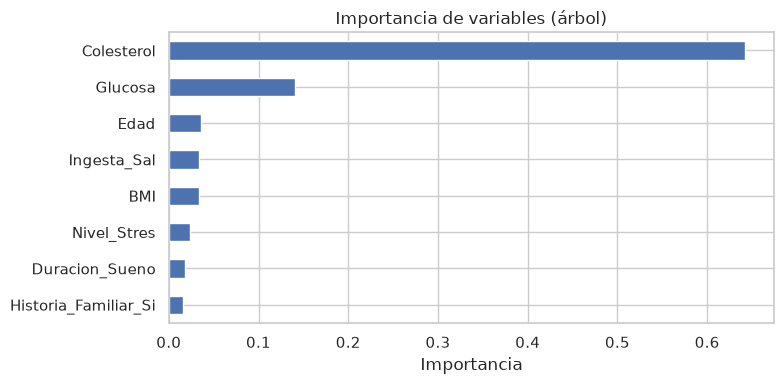

In [47]:
importancias = arbol.named_steps["modelo"].feature_importances_
nombres = arbol.named_steps["prep"].get_feature_names_out()
imp = pd.Series(importancias, index=nombres).sort_values(ascending=False).head(8)
imp.index = imp.index.str.replace(r"^(num|cat)__", "", regex=True)

imp.plot.barh(figsize=(8, 4)); plt.gca().invert_yaxis()
plt.title("Importancia de variables (árbol)"); plt.xlabel("Importancia")
plt.tight_layout(); plt.show()

vemos que la importancia definitiva radica en el colesterol, después sigue una relevancia significativa para la glucosa. Veamos la lista completa:

In [48]:
(pd.Series(importancias, index=nombres)
   .rename_axis(None)
   .rename(lambda x: x.replace("cat__", "").replace("num__", ""))
   .sort_values(ascending=False)
   .rename("importancia")
   .to_frame())

,importancia
Colesterol,0.642349
Glucosa,0.140105
Edad,0.035727
Ingesta_Sal,0.033975
BMI,0.033418
Nivel_Stres,0.023329
Duracion_Sueno,0.018275
Historia_Familiar_Si,0.015344
Enfermedad_Corazon_No,0.014477
Medicacion_Diuretico,0.014103


Las variables que más usa el árbol son Colesterol y glucosa, seguidas de edad ingesta sal y bmi

### Con k-vecinos más cercanos (KNN)

Utilizamos validación cruzada nuevamente, en este caso sí necesitamos hacer un escalado. Aunque no necesitamos imputar, el pipeline llevará imputación + one-hot.

#### Escalado

In [49]:
prep_knn = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer()),
        ("esc", StandardScaler())
    ]), numericas),

    ("cat", Pipeline([
        ("imp", SimpleImputer()),
        ("oh", OneHotEncoder(handle_unknown="ignore"))
    ]), categoricas),
])

pipeline_knn = Pipeline([
    ("prep", prep_knn),
    ("modelo", KNeighborsClassifier())
])

grid_knn = GridSearchCV(
    pipeline_knn,
    param_grid={
        "prep__num__imp__strategy": ["mean", "median"],
        "prep__cat__imp__strategy": ["most_frequent", "constant"],
        "modelo__n_neighbors": [1, 2, 3, 4, 5]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid_knn.best_params_)

Mejores hiperparámetros: {'modelo__n_neighbors': 5, 'prep__cat__imp__strategy': 'most_frequent', 'prep__num__imp__strategy': 'mean'}


Veamos la curva de validación, recordemos que la complejidad funciona al revés

In [50]:
knn = grid_knn.best_estimator_
print("Mejor exactitud CV (KNN escalado):", round(grid_knn.best_score_, 3))

Mejor exactitud CV (KNN escalado): 0.891


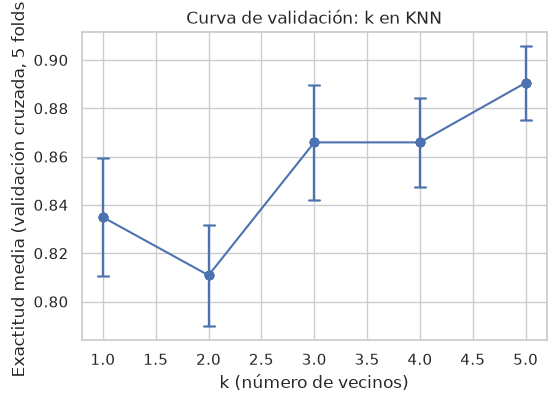

In [51]:
resultados_knn = pd.DataFrame(grid_knn.cv_results_).sort_values("param_modelo__n_neighbors")

plt.figure(figsize=(6, 4))
plt.errorbar(resultados_knn["param_modelo__n_neighbors"].astype(int),
             resultados_knn["mean_test_score"],
             yerr=resultados_knn["std_test_score"], marker="o", capsize=4)
plt.xlabel("k (número de vecinos)")
plt.ylabel("Exactitud media (validación cruzada, 5 folds)")
plt.title("Curva de validación: k en KNN")
plt.show()

Aquí 5 trae el mejor ajuste para el modelo 

#### Sin escalado

In [53]:
grid_knn_sin = GridSearchCV(
    Pipeline([
        ("prep", prep_arbol),   # prep_arbol no realiza escalado
        ("modelo", KNeighborsClassifier())
    ]),
    param_grid={
        "modelo__n_neighbors": [1, 2, 3, 4, 5]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn_sin.fit(X_train, y_train)

knn_sin = grid_knn_sin.best_estimator_

print("Mejores hiperparámetros:", grid_knn_sin.best_params_)
print("Mejor exactitud CV (KNN sin escalar):", round(grid_knn_sin.best_score_, 3))

Mejores hiperparámetros: {'modelo__n_neighbors': 5}
Mejor exactitud CV (KNN sin escalar): 0.902


### Evaluación

Vamos a hacer uso del test en este momento.

In [54]:
print("Exactitud en test:")
print("  Árbol:             ", round(accuracy_score(y_test, arbol.predict(X_test)), 3))
print("  KNN (escalado):    ", round(accuracy_score(y_test, knn.predict(X_test)), 3))
print("  KNN (sin escalar): ", round(accuracy_score(y_test, knn_sin.predict(X_test)), 3))

Exactitud en test:
  Árbol:              0.866
  KNN (escalado):     0.864
  KNN (sin escalar):  0.874


---
# STAND BY

In [55]:
resumen_train_test = pd.DataFrame({
    "Modelo": ["Árbol", "KNN (escalado)", "KNN (sin escalar)"],
    "Exactitud train": [
        accuracy_score(y_train, arbol.predict(X_train)),
        accuracy_score(y_train, knn.predict(X_train)),
        accuracy_score(y_train, knn_sin.predict(X_train)),
    ],
    "Exactitud test": [
        accuracy_score(y_test, arbol.predict(X_test)),
        accuracy_score(y_test, knn.predict(X_test)),
        accuracy_score(y_test, knn_sin.predict(X_test)),
    ],
})
resumen_train_test["Diferencia (train - test)"] = (
    resumen_train_test["Exactitud train"] - resumen_train_test["Exactitud test"])
resumen_train_test.round(3)

,Modelo,Exactitud train,Exactitud test,Diferencia (train - test)
0,Árbol,0.972,0.866,0.105
1,KNN (escalado),0.932,0.864,0.068
2,KNN (sin escalar),0.923,0.874,0.049


Hay poco sobreajuste, el modelo

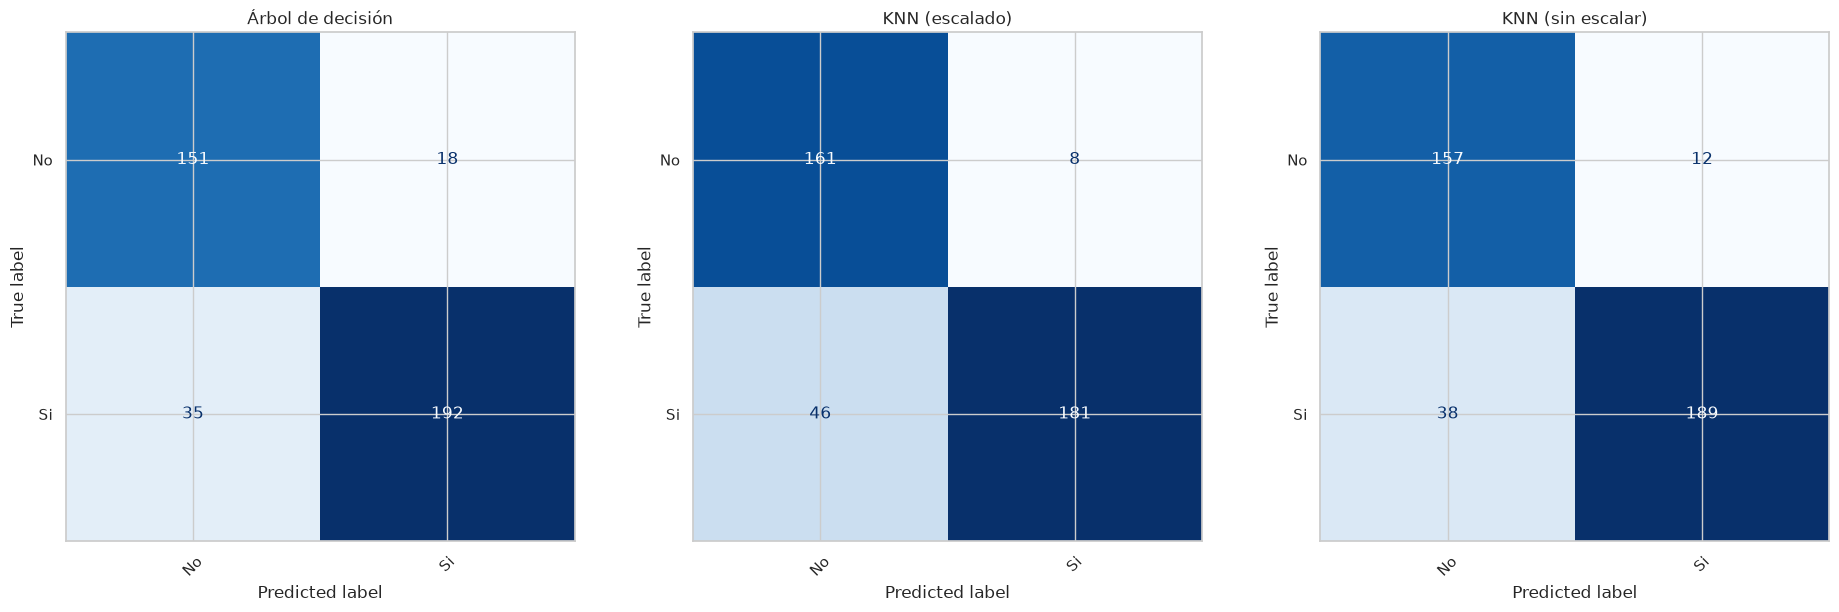

In [56]:
fig, ax = plt.subplots(1, 3, figsize=(19, 6))
ConfusionMatrixDisplay.from_estimator(arbol, X_test, y_test, ax=ax[0],
    xticks_rotation=45, cmap="Blues", colorbar=False)
ax[0].set_title("Árbol de decisión")
ConfusionMatrixDisplay.from_estimator(knn, X_test, y_test, ax=ax[1],
    xticks_rotation=45, cmap="Blues", colorbar=False)
ax[1].set_title("KNN (escalado)")
ConfusionMatrixDisplay.from_estimator(knn_sin, X_test, y_test, ax=ax[2],
    xticks_rotation=45, cmap="Blues", colorbar=False)
ax[2].set_title("KNN (sin escalar)")
plt.tight_layout(); plt.show()

---



Usamos f2

In [58]:
from sklearn.metrics import f1_score
# FALTA PONER F2
print("F2 macro árbol:            ", round(f1_score(y_test, arbol.predict(X_test), average="macro"), 3))
print("F2 macro KNN (escalado):    ", round(f1_score(y_test, knn.predict(X_test), average="macro"), 3))
print("F2 macro KNN (sin escalar): ", round(f1_score(y_test, knn_sin.predict(X_test), average="macro"), 3))

F2 macro árbol:             0.865
F2 macro KNN (escalado):     0.863
F2 macro KNN (sin escalar):  0.873


boostrapping

In [63]:

# Mejor modelo ya entrenado
mejor_modelo = grid_arbol.best_estimator_

# Predicciones sobre el conjunto de test
y_pred = mejor_modelo.predict(X_test)

# Accuracy original
accuracy_original = accuracy_score(y_test, y_pred)

# Número de muestras bootstrap
n_bootstrap = 1000

# Generador aleatorio
rng = np.random.default_rng(42)

# Convertir a arreglos para facilitar el muestreo
y_test_array = np.array(y_test)
y_pred_array = np.array(y_pred)

accuracies_bootstrap = []

for i in range(n_bootstrap):

    # Muestreo con reemplazo de los índices del test
    indices = rng.choice(
        len(y_test_array),
        size=len(y_test_array),
        replace=True
    )

    # Valores correspondientes a la muestra bootstrap
    y_boot = y_test_array[indices]
    pred_boot = y_pred_array[indices]

    # Accuracy de la muestra
    accuracy_boot = accuracy_score(y_boot, pred_boot)

    accuracies_bootstrap.append(accuracy_boot)

# Convertir a numpy array
accuracies_bootstrap = np.array(accuracies_bootstrap)

# Intervalo de confianza del 95 %
limite_inferior = np.percentile(accuracies_bootstrap, 2.5)
limite_superior = np.percentile(accuracies_bootstrap, 97.5)

print("Accuracy original:", round(accuracy_original, 3))
print("Media bootstrap:", round(accuracies_bootstrap.mean(), 3))
print(
    "Intervalo de confianza del 95%:",
    round(limite_inferior, 3),
    "-",
    round(limite_superior, 3)
)

Accuracy original: 0.866
Media bootstrap: 0.867
Intervalo de confianza del 95%: 0.831 - 0.897


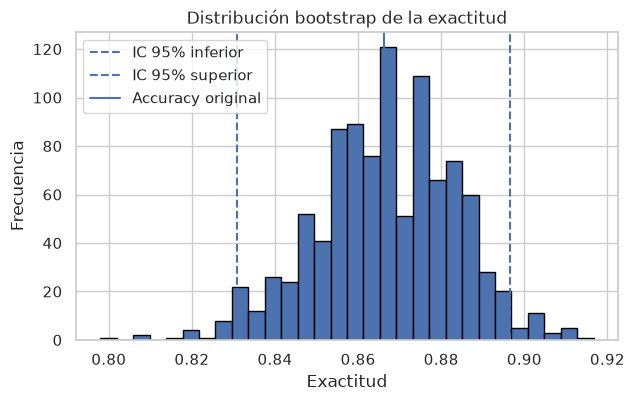

In [64]:
plt.figure(figsize=(7, 4))

plt.hist(
    accuracies_bootstrap,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    limite_inferior,
    linestyle="--",
    label="IC 95% inferior"
)

plt.axvline(
    limite_superior,
    linestyle="--",
    label="IC 95% superior"
)

plt.axvline(
    accuracy_original,
    linestyle="-",
    label="Accuracy original"
)

plt.xlabel("Exactitud")
plt.ylabel("Frecuencia")
plt.title("Distribución bootstrap de la exactitud")

plt.legend()

plt.show()

In [66]:
# Recuperar el mejor pipeline ya entrenado
mejor_arbol = grid_arbol.best_estimator_

# Obtener preprocesador y árbol
prep = mejor_arbol.named_steps["prep"]
arbol = mejor_arbol.named_steps["modelo"]

# Obtener nombres de las variables después del preprocesamiento
nombres_variables = prep.get_feature_names_out()

# Feature importance
importancias = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": arbol.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

print(importancias)

                          Variable  Importancia
3                  num__Colesterol     0.642349
6                     num__Glucosa     0.140105
0                        num__Edad     0.035727
1                 num__Ingesta_Sal     0.033975
5                         num__BMI     0.033418
2                 num__Nivel_Stres     0.023329
4              num__Duracion_Sueno     0.018275
13       cat__Historia_Familiar_Si     0.015344
19      cat__Enfermedad_Corazon_No     0.014477
8        cat__Medicacion_Diuretico     0.014103
15      cat__Actividad_Fisica_Baja     0.008065
17                 cat__Fumador_No     0.007855
10         cat__Medicacion_Ninguna     0.007319
12       cat__Historia_Familiar_No     0.003403
14      cat__Actividad_Fisica_Alta     0.002257
7   cat__Medicacion_BloqueadorBeta     0.000000
9     cat__Medicacion_InhibidorACE     0.000000
11            cat__Medicacion_Otro     0.000000
16  cat__Actividad_Fisica_Moderada     0.000000
18                 cat__Fumador_Si     0

In [67]:
print(importancias.head(10))

                      Variable  Importancia
3              num__Colesterol     0.642349
6                 num__Glucosa     0.140105
0                    num__Edad     0.035727
1             num__Ingesta_Sal     0.033975
5                     num__BMI     0.033418
2             num__Nivel_Stres     0.023329
4          num__Duracion_Sueno     0.018275
13   cat__Historia_Familiar_Si     0.015344
19  cat__Enfermedad_Corazon_No     0.014477
8    cat__Medicacion_Diuretico     0.014103


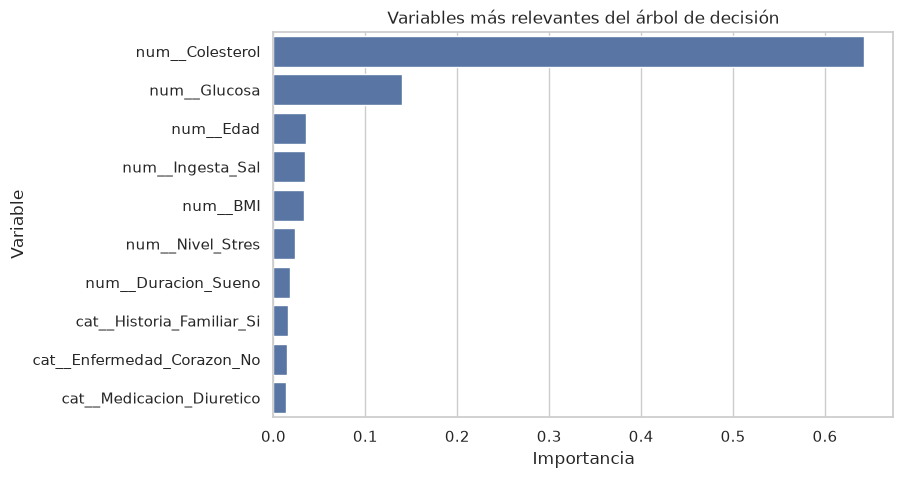

In [69]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importancias.head(10),
    x="Importancia",
    y="Variable"
)

plt.title("Variables más relevantes del árbol de decisión")
plt.xlabel("Importancia")
plt.ylabel("Variable")

plt.show()

In [70]:
reglas = export_text(
    arbol,
    feature_names=list(nombres_variables),
    max_depth=3
)

print(reglas)

|--- num__Colesterol <= 204.85
|   |--- num__Glucosa <= 119.45
|   |   |--- num__Colesterol <= 187.15
|   |   |   |--- num__BMI <= 34.00
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- num__BMI >  34.00
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- num__Colesterol >  187.15
|   |   |   |--- cat__Fumador_No <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- cat__Fumador_No >  0.50
|   |   |   |   |--- truncated branch of depth 5
|   |--- num__Glucosa >  119.45
|   |   |--- num__Colesterol <= 184.80
|   |   |   |--- cat__Historia_Familiar_Si <= 0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- cat__Historia_Familiar_Si >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- num__Colesterol >  184.80
|   |   |   |--- num__Edad <= 49.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- num__Edad >  49.50
|   |   |   |   |--- class: Si
|--- num__Colesterol >  204.85
|   |--- num__Cole

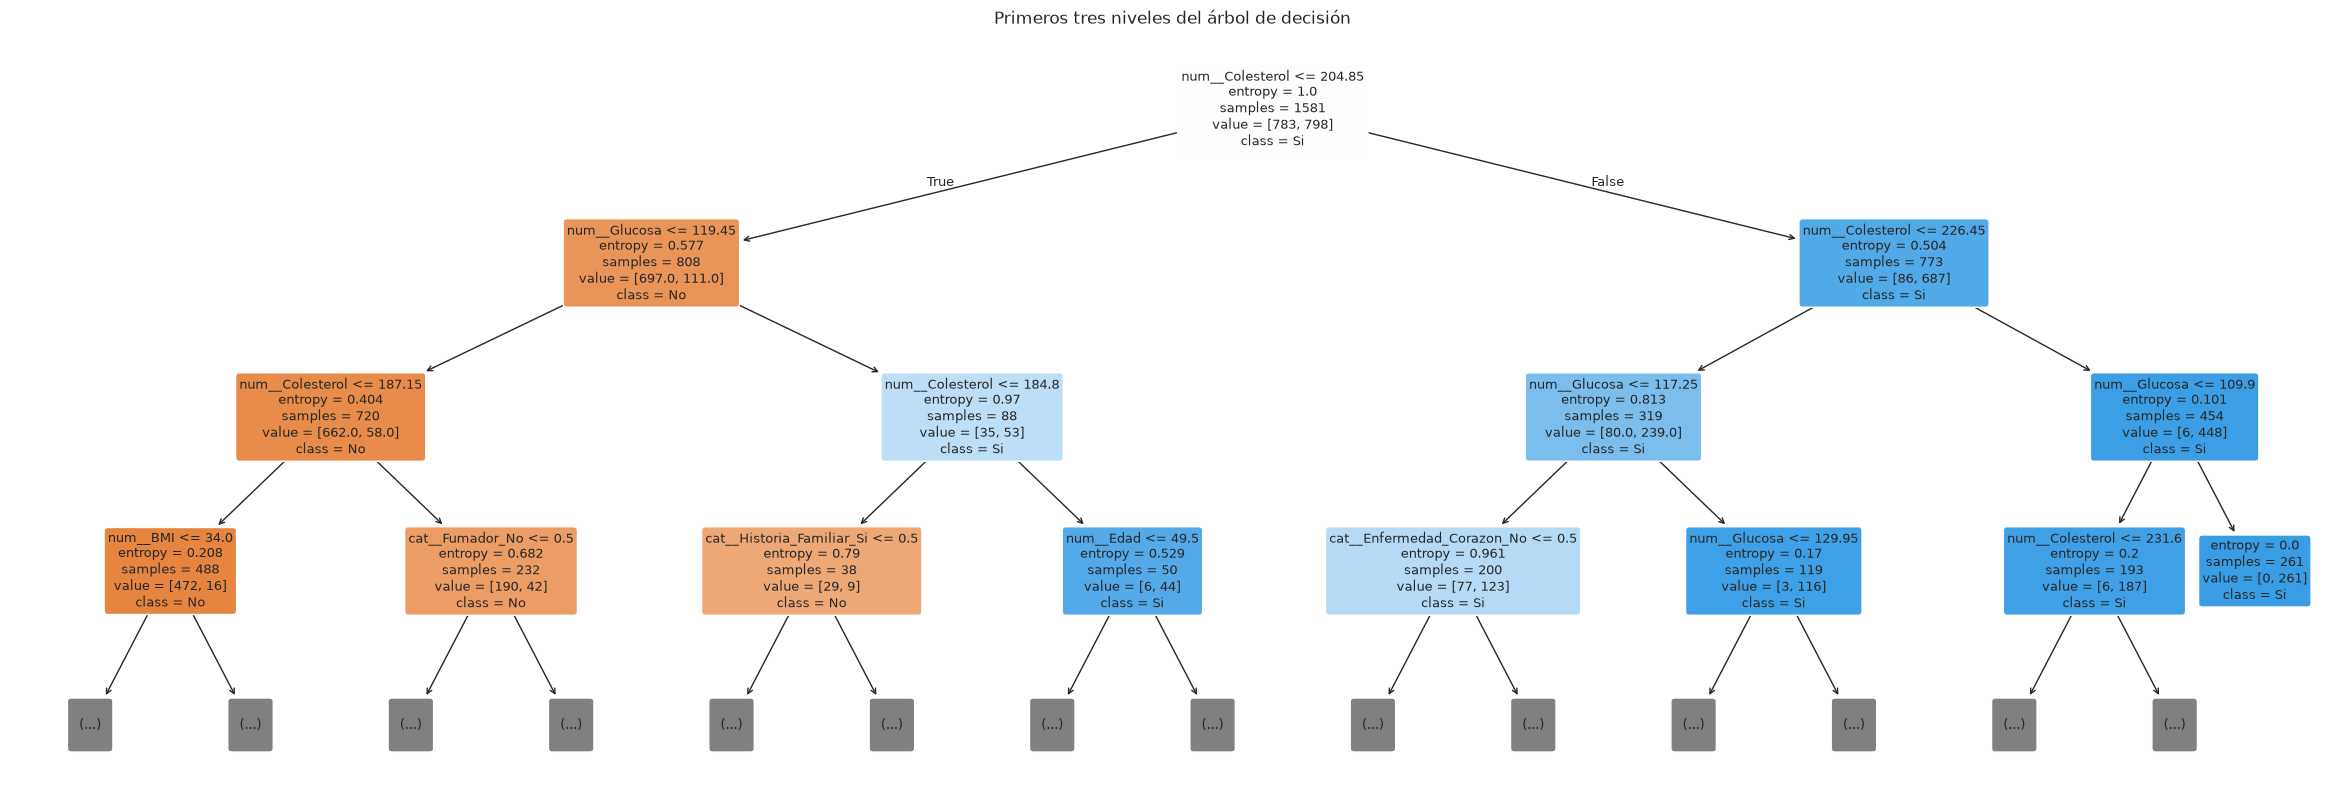

In [73]:
plt.figure(figsize=(30, 10))

plot_tree(
    arbol,
    feature_names=nombres_variables,
    class_names=[str(c) for c in arbol.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Primeros tres niveles del árbol de decisión")
plt.show()